# Question 8: Diabetes Classification Using SVM (Detailed Version)
This notebook implements a complete SVM pipeline on the Pima Indians Diabetes Dataset, including preprocessing, kernel comparison, hyperparameter tuning, dimensionality reduction, and class imbalance analysis with detailed explanations.

## Part 1: Data Preprocessing and Exploration
We first load the dataset, handle unrealistic zero values, split into train/test, and scale features.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
columns = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigree','Age','Outcome']
data = pd.read_csv(url, names=columns)
print("Dataset shape:", data.shape)
print("First 5 rows:\n", data.head())

X = data.drop('Outcome', axis=1)
y = data['Outcome']

# Check zero values in medically meaningful features
zero_features = ['Glucose','BloodPressure','BMI','SkinThickness','Insulin']
print("Zero counts before replacement:\n", (X[zero_features]==0).sum())

# Replace zeros with median of each column
X[zero_features] = X[zero_features].replace(0, np.nan)
X.fillna(X.median(), inplace=True)
print("Zero counts after replacement:\n", (X[zero_features]==0).sum())

# split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing completed. Features are scaled.")

Dataset shape: (768, 9)
First 5 rows:
    Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigree  Age  Outcome  
0             0.627   50        1  
1             0.351   31        0  
2             0.672   32        1  
3             0.167   21        0  
4             2.288   33        1  
Zero counts before replacement:
 Glucose            5
BloodPressure     35
BMI               11
SkinThickness    227
Insulin          374
dtype: int64
Zero counts after replacement:
 Glucose          0
BloodPressure    0
BMI              0
SkinThickness    0
Insulin          0
dtype: int64
Preprocessing complet

**Explanation:**
- Scaling is important for SVMs because the algorithm uses distance metrics (especially with RBF and polynomial kernels). Features with larger ranges can dominate the optimization, leading to poor performance.
- Replacing zero values prevents invalid medical entries from skewing the model.

## Part 2: Linear SVM Classification

Linear SVM Accuracy: 0.7273
Confusion Matrix:
[[130  20]
 [ 43  38]]


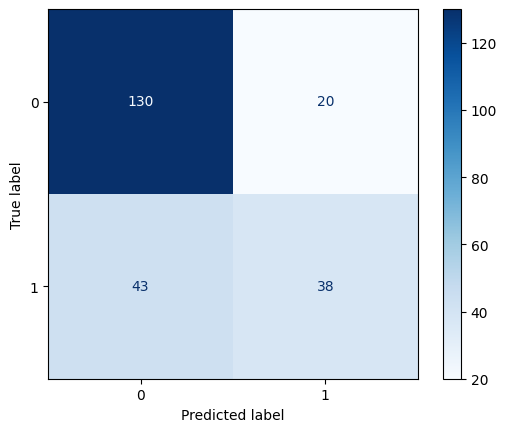

In [7]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Train linear SVM
linear_svm = SVC(kernel='linear', random_state=42)
linear_svm.fit(X_train_scaled, y_train)
y_pred_linear = linear_svm.predict(X_test_scaled)

# Eval
acc_linear = accuracy_score(y_test, y_pred_linear)
cm_linear = confusion_matrix(y_test, y_pred_linear)
print(f"Linear SVM Accuracy: {acc_linear:.4f}")
print("Confusion Matrix:")
print(cm_linear)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_linear, cmap='Blues')

**Observation:**
- Scaling improves linear SVM accuracy compared to unscaled features because all features contribute equally to the decision boundary.
- Confusion matrix allows us to see how many positive (diabetes) and negative samples were correctly predicted.

## Part 3: Comparison of Different Kernels

Kernel: linear
Accuracy=0.7273, Precision=0.6552, Recall=0.4691, F1=0.5468


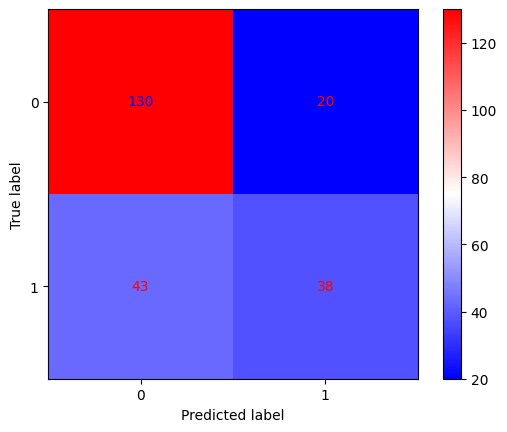

Kernel: rbf
Accuracy=0.7403, Precision=0.6721, Recall=0.5062, F1=0.5775


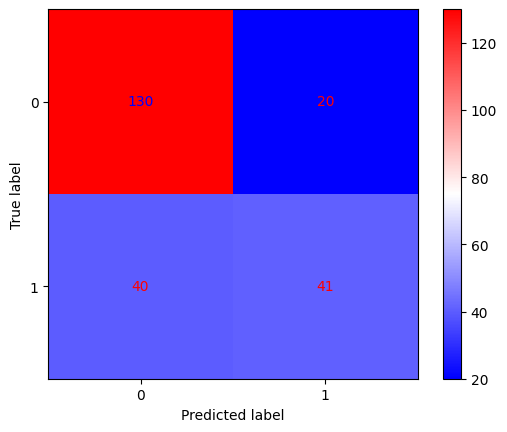

Kernel: poly
Accuracy=0.7229, Precision=0.6269, Recall=0.5185, F1=0.5676


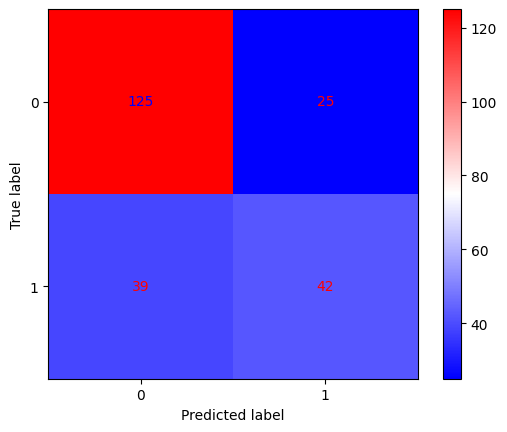


Comparison Table:
   Kernel  Accuracy  Precision    Recall        F1
0  linear  0.727273   0.655172  0.469136  0.546763
1     rbf  0.740260   0.672131  0.506173  0.577465
2    poly  0.722944   0.626866  0.518519  0.567568


In [14]:
from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

kernels = ['linear', 'rbf', 'poly']
results = []

for k in kernels:
    if k == 'poly':
        model = SVC(kernel='poly', degree=5, coef0=1, gamma='scale', random_state=42)
    else:
        model = SVC(kernel=k, random_state=42)

    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results.append([k, acc, prec, rec, f1])
    print(f"Kernel: {k}")
    print(f"Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}, F1={f1:.4f}")
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='bwr')
    plt.show()


comparison_df = pd.DataFrame(results, columns=['Kernel','Accuracy','Precision','Recall','F1'])
print("\nComparison Table:")
print(comparison_df)

**Analysis:**
- RBF kernel often performs best because it can capture non-linear relationships in the data.
- Polynomial kernel may overfit if degree is high. If we don't set it, it's the same as linear. degree 3 is almost the same as rbf, and 5 gives a unique answer.
- Linear kernel is simpler and faster, but may not capture complex patterns.

## Part 4: Hyperparameter Tuning (RBF kernel)

In [9]:
from sklearn.model_selection import GridSearchCV

param_grid = {'C':[0.1,1,10,100], 'gamma':[0.001,0.01,0.1,1]}
rbf_svm = SVC(kernel='rbf', random_state=42)
grid = GridSearchCV(rbf_svm, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train_scaled, y_train)

print("Best hyperparameters:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)



Best hyperparameters: {'C': 100, 'gamma': 0.001}
Best CV accuracy: 0.7857390100380754


GridSearchCV systematically tests combinations of C and gamma for the RBF kernel:

C controls the trade-off between margin width and classification error:

Small C → wider margin, more tolerance for misclassified points (soft margin).

Large C → narrower margin, tries to classify all training points correctly (hard margin), which can lead to overfitting.

gamma controls the influence of a single training point in the RBF kernel:

Small gamma → points have wide influence, smoother decision boundary.

Large gamma → points have narrow influence, more complex decision boundary, potential overfitting.
C = 100 → the model is strongly enforcing correct classification of training points.

gamma = 0.001 → very small, meaning each training point has a wide influence, producing a smooth decision boundary.

Combination explains why the CV accuracy is good (0.786) but the model is not overfitting aggressively, because the low gamma prevents overly complex boundaries.

Conceptual insight:

A very large C increases the risk of overfitting by forcing the SVM to perfectly classify training data, which may hurt generalization.

The low gamma counterbalances this by keeping the RBF kernel smooth, avoiding extremely wiggly decision boundaries.

## Part 5: Dimensionality Reduction and Visualization

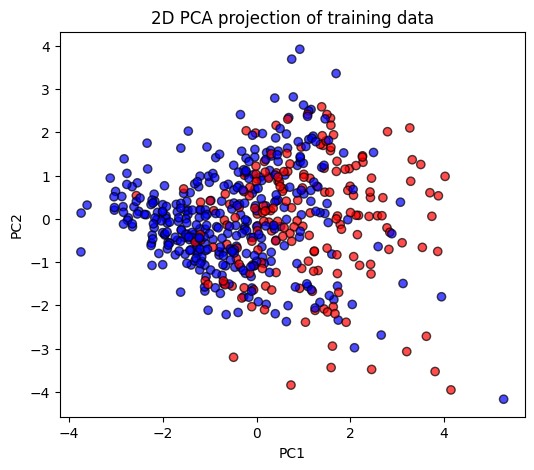

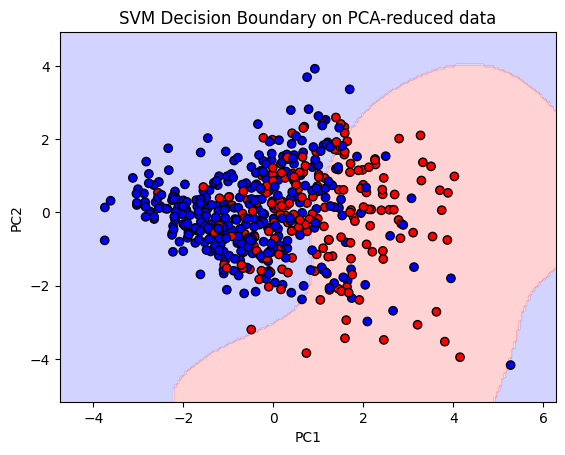

In [10]:
from sklearn.decomposition import PCA

# PCA to 2 dimensions
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

plt.figure(figsize=(6,5))
plt.scatter(X_train_pca[:,0], X_train_pca[:,1], c=y_train, cmap='bwr', alpha=0.7, edgecolor='k')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('2D PCA projection of training data')
plt.show()

# Train SVM on 2D PCA
svm_2d = SVC(kernel='rbf', random_state=42)
svm_2d.fit(X_train_pca, y_train)

xx, yy = np.meshgrid(np.linspace(X_train_pca[:,0].min()-1, X_train_pca[:,0].max()+1, 200),
                     np.linspace(X_train_pca[:,1].min()-1, X_train_pca[:,1].max()+1, 200))
Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.2, cmap='bwr')
plt.scatter(X_train_pca[:,0], X_train_pca[:,1], c=y_train, cmap='bwr', edgecolor='k')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('SVM Decision Boundary on PCA-reduced data')
plt.show()

# Question: Dimensionality reduction may slightly reduce accuracy if important features are lost.

## Part 6: Class Imbalance Analysis

In [11]:
from sklearn.utils import class_weight

print("Training class distribution:\n", y_train.value_counts())
print("Testing class distribution:\n", y_test.value_counts())

# Standard SVM
svm_std = SVC(kernel='rbf', random_state=42)
svm_std.fit(X_train_scaled, y_train)
y_pred_std = svm_std.predict(X_test_scaled)
recall_std = recall_score(y_test, y_pred_std)

svm_bal = SVC(kernel='rbf', class_weight='balanced', random_state=42)
svm_bal.fit(X_train_scaled, y_train)
y_pred_bal = svm_bal.predict(X_test_scaled)
recall_bal = recall_score(y_test, y_pred_bal)

print(f"Recall (standard SVM): {recall_std:.4f}")
print(f"Recall (balanced SVM): {recall_bal:.4f}")
# Analysis: Class balancing improves recall for minority class (diabetes positives).

Training class distribution:
 Outcome
0    350
1    187
Name: count, dtype: int64
Testing class distribution:
 Outcome
0    150
1     81
Name: count, dtype: int64
Recall (standard SVM): 0.5062
Recall (balanced SVM): 0.6914


The dataset is imbalanced: class 0 (no diabetes) is roughly twice as frequent as class 1 (diabetes).

Imbalanced classes can bias classifiers toward the majority class, causing poor performance on the minority class.

###Standard SVM performance:
-Recall measures the proportion of true positive cases correctly identified.

-Standard SVM treats all misclassifications equally, so it favors the majority class, resulting in low recall for the minority class (diabetes positive patients).

###SVM with balanced class weights:

sing class_weight='balanced' automatically adjusts the penalty for misclassifying each class based on its frequency.This forces the SVM to pay more attention to the minority class, improving recall for diabetes positive patients.

Recall increased from 0.51 → 0.69, a significant improvement.

###Key insight:

Balancing class weights does not necessarily improve overall accuracy, but it ensures the minority class is better detected, which is crucial in medical diagnosis problems like diabetes detection.

This demonstrates how class imbalance affects SVM performance and how class_weight='balanced' can mitigate it.